In [1]:
#from bai_utils import *
from tbp_utils_glm_2 import *
import numpy as np
import pandas as pd
from scipy.optimize import fsolve
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from collections import defaultdict
from sklearn.preprocessing import normalize
import ipdb

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    theta = (2*np.random.rand(p)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

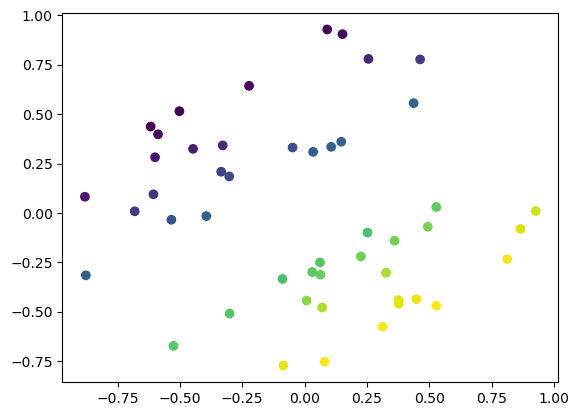

In [3]:
x, y, theta = gen_data(100, p=2, scale=3)
intercept = 0#np.random.rand(1)[0]
#x = x[np.abs(expit(x @ theta + intercept) - 0.3) > 0.2]

x = x[np.abs(expit(x @ theta + intercept) - 0.5) > 0.15,:]
x = x[expit(x @ theta + intercept) < 0.9,:]
x = x[expit(x @ theta + intercept) > 0.1,:]

f = x @ theta
p = expit(f)
plt.scatter(x[:,0],x[:,1], c = p)

In [4]:
m, d = x.shape
prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
                "intercept": 0
              }

prob = logistic_discover(**prob_dict)

In [5]:
x, y, theta = gen_data(100, p=2, scale=3)
intercept = 0#np.random.rand(1)[0]

m, d = x.shape
prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
                "intercept": 0
              }

prob = logistic_discover(**prob_dict)

prob_t = deepcopy(prob)
solver = linear_solver(prob_t, 0.5, 0.01)
g_arms, perf, tau = solver.run(100)
g_arms, perf, tau

/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/th

(array([ 2,  3,  5,  6,  8, 10, 11, 12, 13, 14, 15, 16, 23, 24, 26, 27, 28,
        29, 30, 33, 34, 38, 39, 42, 43, 44, 46, 47, 48, 52, 57, 59, 64, 65,
        67, 69, 70, 71, 73, 74, 75, 77, 78, 80, 82, 83, 84, 85, 86, 93, 95,
        96, 97, 98]),
 ((5, 1), (2, 1)),
 nan)

In [6]:
for i in range(10):
    np.random.seed(i+10)
    x, y, theta = gen_data(50, p=2, scale=3)
    intercept = 0#np.random.rand(1)[0]
        #x = x[np.abs(expit(x @ theta + intercept) - 0.3) > 0.2]

    x = x[np.abs(expit(x @ theta + intercept) - 0.5) > 0.1,:]
        #x = x[expit(x @ theta + intercept) < 0.9,:]
        #x = x[expit(x @ theta + intercept) > 0.1,:]

    f = x @ theta
    p = expit(f)

    m, d = x.shape
    prob_dict = {
                        "m": m,
                        "d": d,
                        "x": x,
                        "theta": theta,
                        "intercept": 0
                      }

    prob = logistic_discover(**prob_dict)

    prob_t = deepcopy(prob)
    solver = glm_rage(prob_t, 0.5, 0.01)
    g_arms, perf, tau = solver.run(1000, 0.05, i)
    print(sum(perf[0]), tau)

0 195
0 393
0 490
0 495
0 296
0 394
0 494
0 393
0 395
0 296


In [28]:
performance = []
tau_list = []
for i in range(30):
    np.random.seed(i+10)
    x, y, theta = gen_data(60, p=2, scale=10)
    intercept = 0#np.random.rand(1)[0]
        #x = x[np.abs(expit(x @ theta + intercept) - 0.3) > 0.2]

    x = x[np.abs(expit(x @ theta + intercept) - 0.5) > 0.1,:]
    print(x.shape)
        #x = x[expit(x @ theta + intercept) < 0.9,:]
        #x = x[expit(x @ theta + intercept) > 0.1,:]

    f = x @ theta
    p = expit(f)

    m, d = x.shape
    prob_dict = {
                        "m": m,
                        "d": d,
                        "x": x,
                        "theta": theta,
                        "intercept": 0
                      }

    prob = logistic_discover(**prob_dict)

    prob_t = deepcopy(prob)
    solver = lazy_TS(prob_t, 0.5, 0.01)
    g_arms, perf, tau = solver.run(1000, 0.05, i)
    print(sum(perf[0]), tau)
    performance.append(sum(perf[0]))
    tau_list.append(tau)
    

(52, 2)
0 nan
(50, 2)
2 nan
(50, 2)
0 624
(53, 2)
0 nan
(46, 2)
0 518
(54, 2)
0 nan
(55, 2)
0 nan
(55, 2)
0 245
(53, 2)


/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/th

0 nan
(50, 2)
0 nan
(55, 2)
0 nan
(56, 2)
0 nan
(51, 2)
0 nan
(53, 2)


/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))


0 949
(50, 2)
0 nan
(52, 2)


/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/th

/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_glm_2.py:26: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/th

0 nan
(50, 2)
0 267
(53, 2)
0 792
(53, 2)
0 nan
(48, 2)
0 nan
(50, 2)
0 495
(54, 2)
0 252
(48, 2)
0 nan
(54, 2)
0 nan
(48, 2)
0 nan
(56, 2)
0 nan
(57, 2)
0 nan
(53, 2)
0 nan
(55, 2)
0 nan
(51, 2)
0 106


In [29]:
(np.array(performance) > 0).mean(), np.array(tau_list).mean()

(0.03333333333333333, nan)

In [147]:
solver.prob.actions

[12, 5, 0]

In [180]:
rewards = solver.prob.x @ solver.theta_hat + solver.intercept_hat
gaps = np.abs(rewards - logit(solver.rho))

amb_arms = np.where(gaps == 0)[0]

#gaps = np.delete(gaps, amb_arms, 0)

#gaps = gaps.reshape(len(gaps), 1)
gaps

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [177]:
design = np.ones(solver.prob.m)
design /= design.sum()
        # maximum number of iterations
max_iter = 1000
        # construct Y
        #rewards = expit(self.prob.x @ self.theta_hat + self.intercept_hat)
rewards = solver.prob.x @ solver.theta_hat + solver.intercept_hat
gaps = np.abs(rewards - logit(solver.rho))
        #bad_arms = np.where(gaps <= 0)[0]
amb_arms = np.where(gaps == 0)[0]
        #good_arms = np.where(gaps > 0)[0]
gaps = np.delete(gaps, amb_arms, 0)
        #gaps = np.delete(gaps, self.best_arm_hat, 0)
gaps = gaps.reshape(len(gaps), 1)
        #X = self.prob.x[good_arms, :]
X = np.delete(solver.prob.x, amb_arms, 0)
X = (1 / gaps) * X
_I = np.ones((solver.prob.d, 1))
for count in range(1, max_iter):
    A_inv = np.linalg.pinv(solver.prob.x.T @ np.diag(design) @ solver.prob.x)
    H_inv = np.linalg.pinv(solver.prob.x.T@ np.diag(design * solver.mean_hat * (1-solver.mean_hat)) @ solver.prob.x)
    U, D, V = np.linalg.svd(H_inv)
            #Ainvhalf = U @ np.diag(np.sqrt(D)) @ V.T
    Hinvhalf = U @ np.diag(np.sqrt(D)) @ V.T

            #newX = (X @ Ainvhalf)**2
    newX = (X @ Hinvhalf)**2
    phi = newX @ _I  # np.ones((newY.shape[1], 1))

    idx = np.argmax(phi)
    x = X[idx, :, None]
            #g = ((self.prob.x @ A_inv @ x) * (self.prob.x @ A_inv @ x)).flatten()
    g = ((solver.prob.x @ H_inv @ x) * (solver.prob.x @ H_inv @ x)).flatten()
    g_idx = np.argmax(g)

    gamma = 2 / (count + 2)
    design_update = -gamma * design
    design_update[g_idx] += gamma

    relative = np.linalg.norm(design_update) / (np.linalg.norm(design))

    design += design_update

            #if count % 100 == 0:
            #   print(('design status %s, %s, %s' %(count, relative, np.max(rho))))
            #    logging.debug('design status %s, %s, %s, %s' %
            #                  (self.seed, count, relative, np.max(rho)))

    if relative < 0.01:
            #    logging.debug('design status %s, %s, %s, %s' %
            #                  (self.seed, count, relative, np.max(rho)))
        break

idx_fix = np.where(design < 1e-5)[0]
design[idx_fix] = 0
design /= np.sum(design)
design, np.max(phi)
    

ValueError: attempt to get argmax of an empty sequence

In [176]:
solver.__optimal_allocation(solver.design)

AttributeError: 'lazy_TS' object has no attribute '__optimal_allocation'

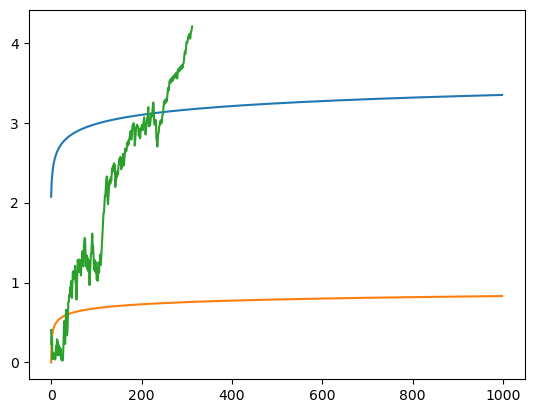

In [126]:
t = np.arange(1,1000)
delta = 0.1
#plt.plot(np.sqrt(solver.prob.d * np.log((1 + t) / delta)))#
plt.plot(np.sqrt(solver.prob.d + np.log((t) / delta)))#
plt.plot(np.sqrt(.1*np.log(t)))
plt.plot(solver.ratio_hist)#

In [55]:
def h(u):
    return u - np.log(u)

def func(x, y):
    return h(x) - y

def h_inv(x):
    return fsolve(func, 1,args=(x))[0]

def h_tild(x, z):
    if x >= h(1 / np.log(z)):
        return np.exp(1/h_inv(x))*h_inv(x)
    else:
        return z*(x-np.log(np.log(z)))

def C_exp(x):
    return 2 * h_tild((h_inv(1+x)+ np.log(2*(np.pi**2/6)))/2, 3/2)

In [65]:
2*C_exp(np.log((solver.prob.m-1)/delta)/2)

27.09813297280853

In [58]:
delta

0.05

In [70]:
6*np.log(np.log(t/2)+1) + 2*C_exp(np.log((solver.prob.m-1)/delta)/2)

array([20.0098106 , 27.09813297, 29.14034269, ..., 39.91484578,
       39.9150484 , 39.91525096])

In [68]:
(3*np.log(1+np.log(1+np.array(solver.prob.T_hist))).sum(1)).shape

(3500,)

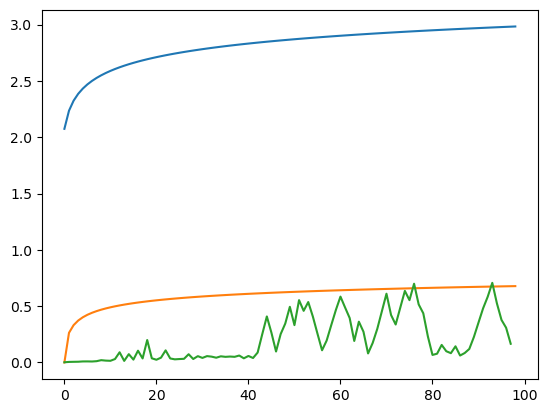

In [116]:
t = np.arange(1,100)
delta = 0.1
#plt.plot(np.sqrt(solver.prob.d * np.log((1 + t) / delta)))#
plt.plot(np.sqrt(solver.prob.d + np.log((t) / delta)))#
plt.plot(np.sqrt(.1*np.log(t)))
plt.plot(solver.ratio_hist)#

(array([49.,  4., 13.,  0.,  2.,  0.,  6.,  1., 16.,  9.]),
 array([ 0. ,  6.1, 12.2, 18.3, 24.4, 30.5, 36.6, 42.7, 48.8, 54.9, 61. ]),
 <BarContainer object of 10 artists>)

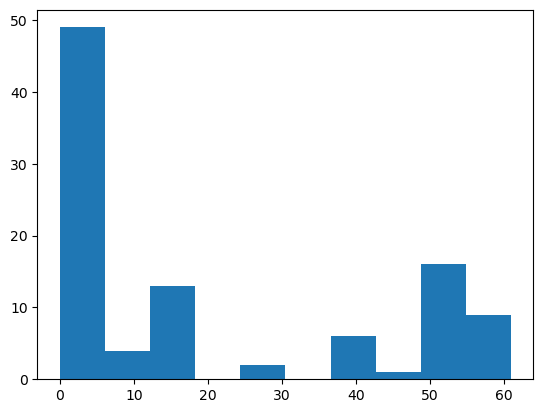

In [100]:
plt.hist(np.array(solver.prob.actions))

In [101]:
prob_t = deepcopy(prob)
solver = GLGapE(prob_t, 0.5, 0.01, 10)
g_arms, perf, tau = solver.run(3000, 0.05, 0)

In [102]:
g_arms, perf, tau

(array([ 1,  7,  8,  9, 12, 17, 18, 22, 26, 28, 30, 34, 37, 41, 42, 47, 48,
        50, 51, 52, 54, 55, 57, 62, 66, 67, 72, 74, 75, 76, 77, 78, 81, 86]),
 ((0, 0), (0, 0)),
 nan)

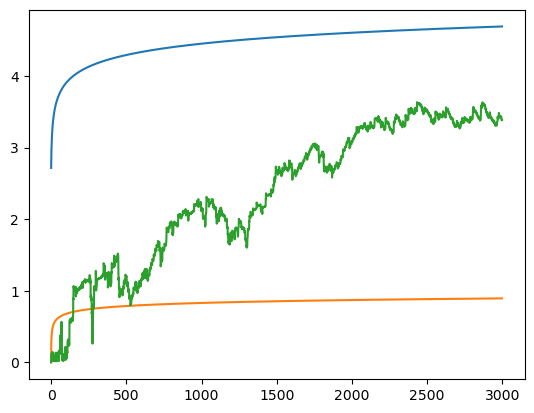

In [103]:
t = np.arange(1,3000)
delta = 0.05
plt.plot(np.sqrt(solver.prob.d * np.log((1 + t) / delta)))#
plt.plot(np.sqrt(.1*np.log(t)))
plt.plot(solver.ratio_hist)#

(array([1.970e+02, 0.000e+00, 1.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        1.000e+00, 0.000e+00, 1.425e+03, 1.375e+03]),
 array([2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5, 6. , 6.5, 7. ]),
 <BarContainer object of 10 artists>)

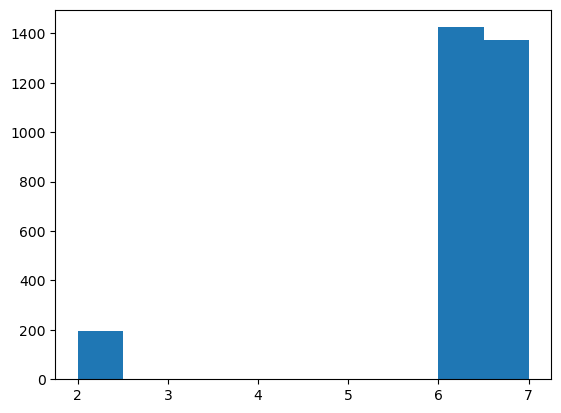

In [26]:
plt.hist(np.array(solver.prob.actions))

In [42]:
x, y, theta = gen_data(100, p=2, scale=3)
intercept = 0#np.random.rand(1)[0]
#x = x[np.abs(expit(x @ theta + intercept) - 0.3) > 0.2]

x = x[np.abs(expit(x @ theta + intercept) - 0.5) > 0.15,:]
x = x[expit(x @ theta + intercept) < 0.9,:]
x = x[expit(x @ theta + intercept) > 0.1,:]

In [43]:
m, d = x.shape
prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
                "intercept": 0
              }

prob = logistic_discover(**prob_dict)

In [186]:
i=0

100
100
100
100


(array([ 1,  2,  4,  5,  7,  8, 10, 15, 18, 21, 22, 23, 25, 26, 30, 31, 32,
        35, 37, 38, 40, 45, 50, 51, 55, 56, 58, 63, 64, 65, 66, 68, 69, 71,
        72, 74, 75, 76, 77, 81, 83, 85, 88, 89, 91, 95, 98, 99]),
 ((1, 1), (0, 0)),
 394)

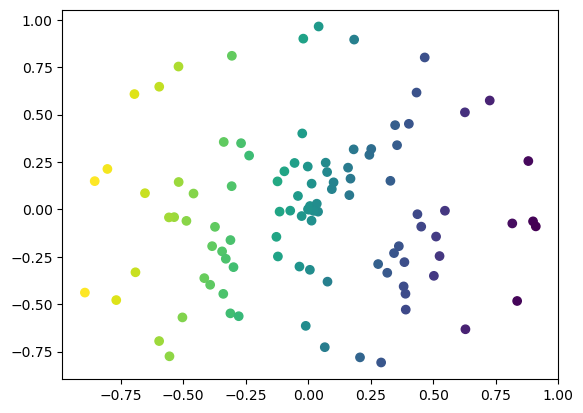

In [210]:
x, y, theta = gen_data(100, p=2, scale=2)
intercept = 0#np.random.rand(1)[0]
#x = x[np.abs(expit(x @ theta + intercept) - 0.3) > 0.2]

#x = x[np.abs(expit(x @ theta + intercept) - 0.5) > 0.15,:]
#x = x[expit(x @ theta + intercept) < 0.9,:]
#x = x[expit(x @ theta + intercept) > 0.1,:]

f = x @ theta
p = expit(f)
plt.scatter(x[:,0],x[:,1], c = p)

m, d = x.shape
prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
                "intercept": 0
              }

prob = logistic_discover(**prob_dict)

prob_t = deepcopy(prob)
solver = glm_rage(prob_t, 0.5, 0.01)
g_arms, perf, tau = solver.run(4000000, 0.05, i)

i = i + 1
g_arms, perf, tau


In [47]:
solver._build_A0()

In [12]:
solver.active_arms

[]

In [10]:
(solver.prob.d**2)*solver.factor

20

In [9]:
theta

array([-2.1405772 , -2.10188706])

(array([49.,  0.,  0., 50.,  0.,  0.,  1.,  0.,  0.,  1.]),
 array([2. , 2.3, 2.6, 2.9, 3.2, 3.5, 3.8, 4.1, 4.4, 4.7, 5. ]),
 <BarContainer object of 10 artists>)

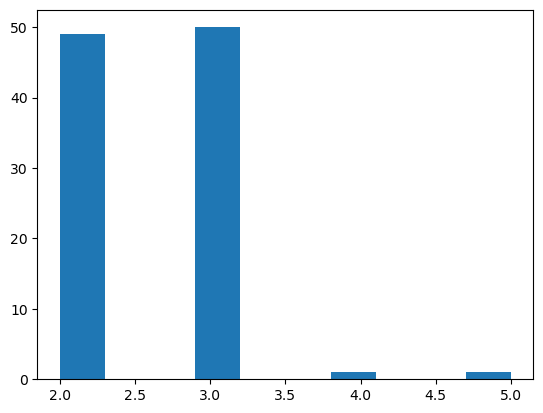

In [8]:
plt.hist(np.array(solver.prob.actions))

In [7]:
expit(solver.prob.x @ solver.theta_hat)[expit(solver.prob.x @ solver.prob.theta)<.3] <.3

array([ True,  True])

In [229]:
a = np.linspace(-100,100,10000).reshape(10000,1)
b = np.linspace(-100,100,10000).reshape(1,10000)

In [231]:
(expit(a) + expit(b) - expit(a + b) <0).sum()

0